**PART A**

In [3]:
### 1. Load and inspect the raw data


from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Use a relative path so the notebook works in Colab and Jupyter.
RAW_FILE = Path("sales_raw.csv")
CLEAN_FILE = Path("cleaned_sales.csv")
UPDATED_FILE = Path("sales_updated.csv")

# Read the original CSV file.
raw_df = pd.read_csv(RAW_FILE)

# Display the first five rows, shape, column names, and data types.
display(raw_df.head())
print("Shape (rows, columns):", raw_df.shape)
print("Column names:", raw_df.columns.tolist())
print("\nData types:")
print(raw_df.dtypes)



,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250


Shape (rows, columns): (21, 6)
Column names: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']

Data types:
transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price         object
dtype: object


In [4]:
### 2. Check data quality



# Check missing values in each column.
print("Missing values by column:")
print(raw_df.isna().sum())

# Count exact duplicate rows.
print("\nExact duplicate rows:", raw_df.duplicated().sum())

# Keep the original raw data unchanged and work on a copy.
df = raw_df.copy()

# Record the number of rows before cleaning.
rows_before = len(df)
print("\nRows before cleaning:", rows_before)


Missing values by column:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Exact duplicate rows: 1

Rows before cleaning: 21


In [8]:
### 3. Clean the data



# Remove exact duplicate records.
df = df.drop_duplicates()

# Normalize text: trim whitespace and use consistent capitalization.
df["region"] = df["region"].astype("string").str.strip().str.title()
df["category"] = df["category"].astype("string").str.strip().str.title()

# Parse dates. Invalid dates become NaT (missing date).
df["sale_date"] = pd.to_datetime(df["sale_date"], errors="coerce")

# Convert numeric columns. Invalid text (such as 'invalid') becomes NaN.
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")

# Remove rows with missing essential values.
df = df.dropna(subset=["sale_date", "region", "category", "quantity", "unit_price"])

# Keep only positive quantities and prices.
df = df[(df["quantity"] > 0) & (df["unit_price"] > 0)]

# Use IQR to identify unusual unit prices.
q1 = df["unit_price"].quantile(0.25)
q3 = df["unit_price"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("Upper IQR limit for unit_price:", upper_limit)
print("Rows flagged as high-price outliers:", (df["unit_price"] > upper_limit).sum())

# Based on the raw data and likely data-entry error, remove the 10,000 price.
df = df[df["unit_price"] <= upper_limit].copy()

# Record row count after cleaning.
rows_after = len(df)
print("\nRows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

# Check that essential missing values and duplicates are gone.
print("\nMissing values after cleaning:")
print(df.isna().sum())
print("Duplicate rows after cleaning:", df.duplicated().sum())

# Display cleaned records.
display(df.head())

### 4. Calculate revenue and summarize


# Calculate revenue for every transaction.
df["revenue"] = df["quantity"] * df["unit_price"]

# Group by region and calculate total revenue.
revenue_by_region = df.groupby("region")["revenue"].sum().sort_values(ascending=False)

print("Revenue by region:")
display(revenue_by_region.reset_index(name="total_revenue"))


Q1: 91.25 Q3: 250.0 IQR: 158.75
Upper IQR limit for unit_price: 488.125
Rows flagged as high-price outliers: 1

Rows before cleaning: 21
Rows after cleaning: 13
Rows removed: 8

Missing values after cleaning:
transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        0
dtype: int64
Duplicate rows after cleaning: 0


,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,2026-10-01,North,Food,2.0,120.0
1,1002,2026-10-01,South,Books,1.0,250.0
2,1003,2026-10-02,North,Food,3.0,110.0
3,1004,2026-10-02,East,Stationery,4.0,50.0
4,1005,2026-10-03,South,Books,2.0,250.0


Revenue by region:


,region,total_revenue
0,North,1470.0
1,South,1035.0
2,East,740.0
3,West,530.0


In [9]:
### 4. Calculate revenue and summarize


# Calculate revenue for every transaction.
df["revenue"] = df["quantity"] * df["unit_price"]

# Group by region and calculate total revenue.
revenue_by_region = df.groupby("region")["revenue"].sum().sort_values(ascending=False)

print("Revenue by region:")
display(revenue_by_region.reset_index(name="total_revenue"))



Revenue by region:


,region,total_revenue
0,North,1470.0
1,South,1035.0
2,East,740.0
3,West,530.0


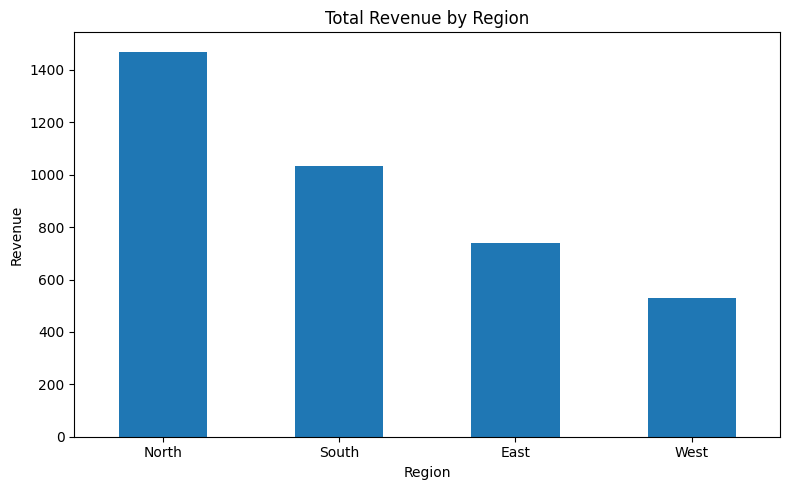

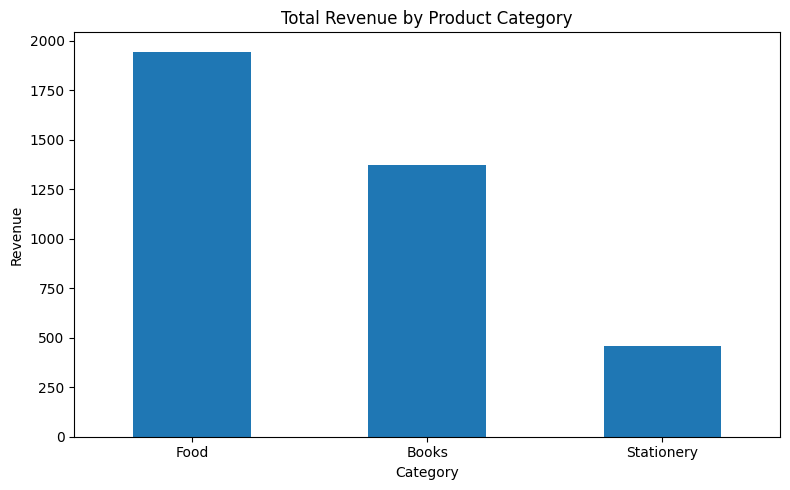

In [10]:
### 5. Create two labelled charts


# Chart 1: Revenue by region.
plt.figure(figsize=(8, 5))
revenue_by_region.plot(kind="bar")
plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Chart 2: Revenue by category.
revenue_by_category = df.groupby("category")["revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
revenue_by_category.plot(kind="bar")
plt.title("Total Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [11]:
## 6. Evidence-based findings


# Find the region and category with the highest revenue.
top_region = revenue_by_region.idxmax()
top_region_revenue = revenue_by_region.max()

top_category = revenue_by_category.idxmax()
top_category_revenue = revenue_by_category.max()

print(f"Finding 1: {top_region} has the highest regional revenue ({top_region_revenue:.2f}).")
print(f"Finding 2: {top_category} is the highest-revenue category ({top_category_revenue:.2f}).")

# Optional: display the revenue totals used for the findings.
print("\nRevenue by region:")
print(revenue_by_region)
print("\nRevenue by category:")
print(revenue_by_category)



Finding 1: North has the highest regional revenue (1470.00).
Finding 2: Food is the highest-revenue category (1945.00).

Revenue by region:
region
North    1470.0
South    1035.0
East      740.0
West      530.0
Name: revenue, dtype: float64

Revenue by category:
category
Food          1945.0
Books         1370.0
Stationery     460.0
Name: revenue, dtype: float64


In [12]:
### 7. Save cleaned data


# Save cleaned data to a separate file; raw input remains unchanged.
df.to_csv(CLEAN_FILE, index=False)

print("Cleaned data saved to:", CLEAN_FILE)
print("Output exists:", CLEAN_FILE.exists())
print("Cleaned rows:", len(df))


Cleaned data saved to: cleaned_sales.csv
Output exists: True
Cleaned rows: 13


**PART B**

In [15]:
## Part B — CSV File Handling & Manipulation (30 marks)

### 1. Load cleaned data and add tax



# Load the cleaned CSV produced in Part A.
sales_df = pd.read_csv(CLEAN_FILE)

# Add tax equal to 5 percent of revenue.
sales_df["tax_amount"] = sales_df["revenue"] * 0.05

# Show the first five rows.
display(sales_df.head())



,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,12.0
1,1002,2026-10-01,South,Books,1.0,250.0,250.0,12.5
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.5
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.0
4,1005,2026-10-03,South,Books,2.0,250.0,500.0,25.0


In [17]:
### 2. Increase Books prices by 10% using `.loc[]`




# Select Books rows and increase their unit_price by 10%.
books_mask = sales_df["category"] == "Books"
sales_df.loc[books_mask, "unit_price"] = sales_df.loc[books_mask, "unit_price"] * 1.10

# Recalculate revenue after the price update.
sales_df["revenue"] = sales_df["quantity"] * sales_df["unit_price"]

# Recalculate tax after revenue changes.
sales_df["tax_amount"] = sales_df["revenue"] * 0.05

print("Books rows after 10% price increase:")
display(sales_df.loc[books_mask, ["transaction_id", "category", "unit_price", "revenue", "tax_amount"]])



Books rows after 10% price increase:


,transaction_id,category,unit_price,revenue,tax_amount
1,1002,Books,275.0,275.0,13.75
4,1005,Books,275.0,550.0,27.50
6,1008,Books,330.0,330.0,16.50
8,1012,Books,352.0,352.0,17.60


In [18]:
### 3. Remove one selected transaction


# Choose an existing transaction_id to remove.
transaction_to_remove = 1019

# Check whether the selected transaction exists.
print("Selected transaction exists:", (sales_df["transaction_id"] == transaction_to_remove).any())

# Remove that transaction.
sales_df = sales_df.loc[sales_df["transaction_id"] != transaction_to_remove].copy()

print("Rows after removing transaction", transaction_to_remove, ":", len(sales_df))



Selected transaction exists: True
Rows after removing transaction 1019 : 12


In [21]:
### 4. Create and remove a temporary review column


# Add a temporary review status column.
sales_df["review_status"] = "Reviewed"

# Remove the temporary column before final export.
sales_df = sales_df.drop(columns=["review_status"])

print("review_status column removed:", "review_status" not in sales_df.columns)


### 5. Save and verify the final CSV
# Save final updated data.
sales_df.to_csv(UPDATED_FILE, index=False)

# Read the saved file again to verify it was written correctly.
verified_df = pd.read_csv(UPDATED_FILE)

print("Saved file:", UPDATED_FILE)
print("First five rows of sales_updated.csv:")
display(verified_df.head())

print("Final column names:")
print(verified_df.columns.tolist())

print("Final shape:", verified_df.shape)

review_status column removed: True
Saved file: sales_updated.csv
First five rows of sales_updated.csv:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,12.00
1,1002,2026-10-01,South,Books,1.0,275.0,275.0,13.75
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.50
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.00
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,27.50


Final column names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']
Final shape: (12, 8)
